In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080214
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp02_hw02
[学号] 20244080214
[机器指纹] ce45d28477f77e24
[RUN_ID] 20244080214-ce45d28477f77e24


### 实验一 Numpy数组与索引

In [2]:
#任务1
import numpy as np

a_int = np.array([1, 2, 3])
a_float = np.array([1.0, 2.0, 3.0])
a_bool = np.array([True, False, True])

for name, arr in [("int", a_int), ("float", a_float), ("bool", a_bool)]:
    print(name, arr.dtype, arr.shape, arr.ndim)

int int64 (3,) 1
float float64 (3,) 1
bool bool (3,) 1


In [6]:
#任务2
import numpy as np

x = np.arange(12)
x34 = x.reshape(3, 4)
x232 = x.reshape(2, 3, 2)
print("原一维:\n", x)
print("(3,4):\n", x34)
print("(2,3,2):\n", x232)

原一维:
 [ 0  1  2  3  4  5  6  7  8  9 10 11]
(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [4]:
#任务3
arr = np.arange(12).reshape(3, 4)
print("第2行:", arr[1], arr[1].shape)           # 形状 (4,)
print("第1至第3列:", arr[:, 0:3], arr[:, 0:3].shape)  # 形状 (3,3)
mask = arr > 6
print("大于6:", arr[mask], arr[mask].shape)     # 布尔索引返回一维

第2行: [4 5 6 7] (4,)
第1至第3列: [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] (3, 3)
大于6: [ 7  8  9 10 11] (5,)


In [7]:
#任务4
a = np.arange(10)
r1 = a[(a < 2) | (a > 7)]
r2 = a[(a > 3) & (a < 7)]
print("小于2 或 大于7:", r1)
print("大于3 且 小于7:", r2)

小于2 或 大于7: [0 1 8 9]
大于3 且 小于7: [4 5 6]


In [8]:
#任务5
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A*B =\n", A * B)
print("np.multiply(A,B) =\n", np.multiply(A, B))
print("A@B =\n", A @ B)
print("np.matmul(A,B) =\n", np.matmul(A, B))

A*B =
 [[ 5 12]
 [21 32]]
np.multiply(A,B) =
 [[ 5 12]
 [21 32]]
A@B =
 [[19 22]
 [43 50]]
np.matmul(A,B) =
 [[19 22]
 [43 50]]


### 实验二 随机抽样、统计与缺失

In [9]:
#任务1
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:", scores.mean())
print("标准差:", scores.std())
print("极差:", scores.max() - scores.min())

样本数: 1000
最小值: 37.58732659930927
最大值: 100.0
均值: 70.18400443523215
标准差: 9.755086339034765
极差: 62.41267340069073


In [10]:
#任务2
pool = np.arange(1, 11)
uniform_sample = np.random.choice(pool, size=5, replace=False)
weights = pool / pool.sum()
weighted_sample = np.random.choice(pool, size=5, replace=False, p=weights)
print("均匀:", uniform_sample)
print("加权:", weighted_sample)

均匀: [ 4  9  2  6 10]
加权: [10  2  8  9  6]


In [11]:
#任务3
orig = np.arange(10)
permuted = np.random.permutation(orig)
print("permutation 前原数组:", orig)
print("permutation 返回:", permuted)

orig2 = np.arange(10).copy()
ret = np.random.shuffle(orig2)
print("shuffle 返回值:", ret)
print("shuffle 后原数组被修改:", orig2)

permutation 前原数组: [0 1 2 3 4 5 6 7 8 9]
permutation 返回: [7 0 5 4 1 8 9 2 6 3]
shuffle 返回值: None
shuffle 后原数组被修改: [0 4 7 6 9 5 1 3 8 2]


In [13]:
#任务4
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan
print("普通均值:", scores_nan.mean())
print("nanmean:", np.nanmean(scores_nan))
print("缺失个数:", np.isnan(scores_nan).sum())

普通均值: nan
nanmean: 70.19620743160239
缺失个数: 3


In [14]:
#任务5
table_data = {
    "序号": np.arange(1, len(scores_nan) + 1),
    "成绩": scores_nan,
}
print(type(table_data), table_data["序号"][:5], table_data["成绩"][:5])

<class 'dict'> [1 2 3 4 5] [74.96714153 68.61735699 76.47688538 85.23029856 67.65846625]


### 实验三 SciPy与Matplotlib

In [15]:
#任务1
from scipy.linalg import solve
A = np.array([[3., 1.], [1., 2.]])
b = np.array([9., 8.])
sol = solve(A, b)
print("解:", sol)
print("A@sol =", A @ sol)

解: [2. 3.]
A@sol = [9. 8.]


In [16]:
#任务2
from scipy.optimize import root
def f(x): return x**2 - 2

r_pos = root(f, x0=1.0)
r_neg = root(f, x0=-1.0)
for name, r in [("正根", r_pos), ("负根", r_neg)]:
    print(name, "success:", r.success, "root:", r.x, "f(root):", f(r.x))

正根 success: True root: [1.41421356] f(root): [-8.8817842e-16]
负根 success: True root: [-1.41421356] f(root): [-8.8817842e-16]


In [17]:
#任务三
from scipy.optimize import minimize
def g(x): return x**2 + x + 2
res = minimize(g, x0=0.0)
print("极小点:", res.x, "函数值:", res.fun)


极小点: [-0.50000001] 函数值: 1.75


In [18]:
#任务4
from scipy import stats
np.random.seed(123)
g1 = np.random.normal(0, 1, 100)
g2 = np.random.normal(1, 1, 100)
t, p = stats.ttest_ind(g1, g2)
print("t =", t, "p =", p)
print("显著(p<0.05)?", p < 0.05)

t = -6.375150151768143 p = 1.2596545903876723e-09
显著(p<0.05)? True


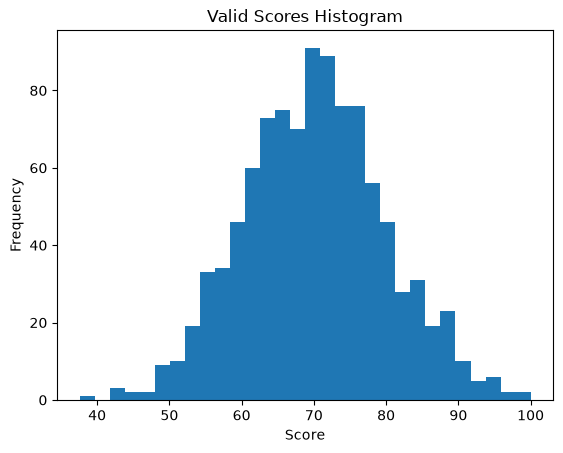

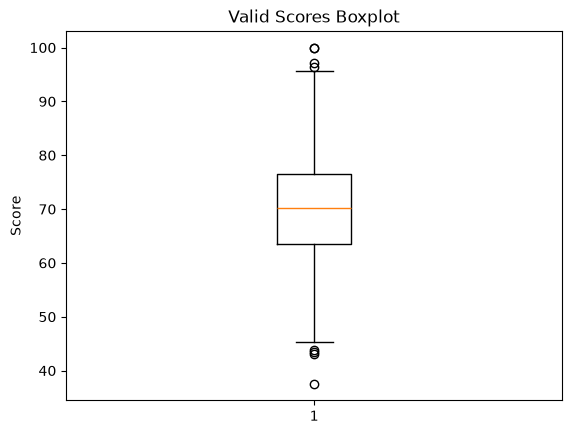

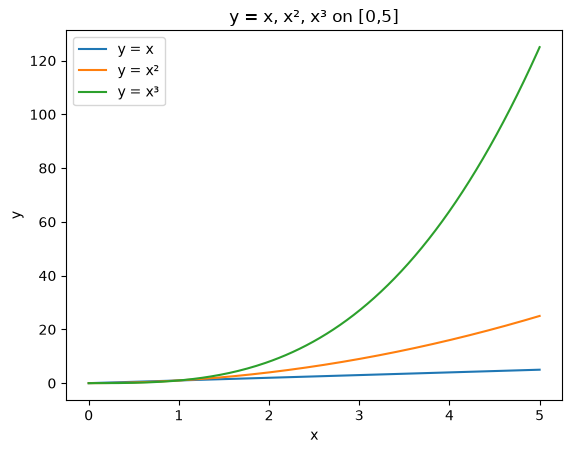

In [19]:
#任务 5
import matplotlib.pyplot as plt
valid = scores_nan[~np.isnan(scores_nan)]

fig, ax = plt.subplots()
ax.hist(valid, bins=30)
ax.set_title("Valid Scores Histogram"); ax.set_xlabel("Score"); ax.set_ylabel("Frequency")
plt.show()

fig, ax = plt.subplots()
ax.boxplot(valid)
ax.set_title("Valid Scores Boxplot"); ax.set_ylabel("Score")
plt.show()

x = np.linspace(0, 5, 200)
fig, ax = plt.subplots()
ax.plot(x, x, label="y = x")
ax.plot(x, x**2, label="y = x²")
ax.plot(x, x**3, label="y = x³")
ax.set_title("y = x, x², x³ on [0,5]"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(); plt.show()

### 实验四 pandas

In [20]:
#任务1
import pandas as pd
records = {
    "Name": ["Alice","Bob","Carol","David","Eva","Frank"],
    "Group": ["A","A","B","B","A","B"],
    "Math": [88,72,91,65,79,84],
    "English": [90,68,85,73,92,77],
    "Python": [95,80,89,70,86,82],
}
df = pd.DataFrame(records).set_index("Name")
cols = ["Math","English","Python"]
df["Total"] = df[cols].sum(axis=1)
df["Average"] = df[cols].mean(axis=1)

print("行索引:", df.index)
print("列名:", df.columns)
print(df.head(3))
print(df.describe())

行索引: Index(['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank'], dtype='str', name='Name')
列名: Index(['Group', 'Math', 'English', 'Python', 'Total', 'Average'], dtype='str')
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [21]:
#任务2
print("loc['Carol']:\n", df.loc["Carol"])
print("iloc[2]:\n", df.iloc[2])
print("Average>=80:\n", df[df["Average"] >= 80])

loc['Carol']:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc[2]:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
Average>=80:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [22]:
# 任务3
print("列均值:\n", df[cols].mean(axis=0))
print("行均值:\n", df[cols].mean(axis=1))

列均值:
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
行均值:
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [23]:
#任务4
df["MaxScore"] = df[cols].apply(max, axis=1)
print(df["MaxScore"])
print(df[cols].agg(["min","mean","max"]))
df["MathRank"] = df["Math"].rank(ascending=False)
print(df["MathRank"])

Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: MaxScore, dtype: int64
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
Name
Alice    2.0
Bob      5.0
Carol    1.0
David    6.0
Eva      4.0
Frank    3.0
Name: MathRank, dtype: float64


In [24]:
#任务5
print(df.groupby("Group")[cols].agg(["count","mean"]))
df["GroupPythonMean"] = df.groupby("Group")["Python"].transform("mean")
print(df[["Group","Python","GroupPythonMean"]])

       Math            English            Python           
      count       mean   count       mean  count       mean
Group                                                      
A         3  79.666667       3  83.333333      3  87.000000
B         3  80.000000       3  78.333333      3  80.333333
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [25]:
#任务6
gmean = df.groupby("Group")["Python"].mean()
keep = gmean[gmean >= 80].index
print("保留的组:", list(keep))
print(df[df["Group"].isin(keep)])

保留的组: ['A', 'B']
      Group  Math  English  Python  Total    Average  MaxScore  MathRank  \
Name                                                                       
Alice     A    88       90      95    273  91.000000        95       2.0   
Bob       A    72       68      80    220  73.333333        80       5.0   
Carol     B    91       85      89    265  88.333333        91       1.0   
David     B    65       73      70    208  69.333333        73       6.0   
Eva       A    79       92      86    257  85.666667        92       4.0   
Frank     B    84       77      82    243  81.000000        84       3.0   

       GroupPythonMean  
Name                    
Alice        87.000000  
Bob          87.000000  
Carol        80.333333  
David        80.333333  
Eva          87.000000  
Frank        80.333333  


In [26]:
#任务7
print("协方差:\n", df[cols].cov())
print("相关系数:\n", df[cols].corr())

协方差:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
相关系数:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
